# GeoIntent — 02: Topology validation
**Post-coursework AI-assisted methodological extension.** Based on the 2025 Geodesignhub team project. This notebook checks the original graph grouping logic, object-level flag alignment and parameter sensitivity. It does not establish real-world classification accuracy. Original partner data are not distributed. Default mode uses fictional geometries; switch to private mode only with permission.

In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
from shapely.geometry import box
from IPython.display import display

USE_PRIVATE_DATA = False
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "raw"


## 1. Inputs and geometry quality
The original uses EPSG:3857. Retain it for baseline comparison; projected units are not necessarily ground metres. The synthetic cases have known place labels for illustration only.

In [2]:
if USE_PRIVATE_DATA:
    # Change DATA to the local directory containing both original files.
    if not (DATA / "survey_responses.csv").exists():
        DATA = ROOT
    survey = pd.read_csv(DATA / "survey_responses.csv")
    polygons = gpd.read_file(DATA / "downloaded_data_polygons.gpkg")
    assert survey.id.is_unique and polygons.id.is_unique
    merged = polygons.merge(survey[["id", "Category"]], on="id", how="left", validate="one_to_one")
    merged = merged.to_crs(3857)
else:
    specs = [("A", "P1", 0,0,10,10), ("B", "P1", 2,0,12,10),
             ("C", "P1", 11,0,21,10), ("D", "P2", 50,0,60,10),
             ("E", "P2", 54,0,64,10), ("F", "P3", 58,0,68,10),
             ("G", "P4", 100,0,110,10), ("H", "P4", 102,2,107,7)]
    merged = gpd.GeoDataFrame({"id":[s[0] for s in specs], "truth":[s[1] for s in specs],
        "Category":["Example"]*len(specs)}, geometry=[box(*s[2:]) for s in specs], crs=3857)
    survey = merged[["id","Category"]].copy()
merged = merged.loc[merged.geometry.notna()].copy()
valid = merged.loc[merged.geometry.is_valid & ~merged.geometry.is_empty & (merged.geometry.area > 0)].copy()
valid["Category"] = valid.Category.fillna("Unknown")
assert valid.id.is_unique
print({"survey_records":len(survey), "spatial_records":len(merged), "valid":len(valid), "excluded":len(merged)-len(valid)})

{'survey_records': 8, 'spatial_records': 8, 'valid': 8, 'excluded': 0}


## 2. Original grouping logic
Buffer candidates, original polygon IoU, undirected graph and connected components. Add isolates explicitly, equivalent to assigning them separately in the original notebook. Split components by category afterwards; numeric group names need not match the original prefixes.

In [3]:
def iou(a,b):
    u = a.union(b).area
    return a.intersection(b).area/u if u else 0.0

def candidate_scores(frame, radius=20):
    left = frame[["id", "geometry"]].copy()
    left.geometry = left.geometry.buffer(radius) if radius else left.geometry
    pairs = gpd.sjoin(left, frame[["id","geometry"]], how="inner", predicate="intersects")
    geom = frame.set_index("id").geometry
    seen, scores = set(), []
    for a,b in zip(pairs.id_left, pairs.id_right):
        if a == b: continue
        key = frozenset((a,b))
        if key in seen: continue
        seen.add(key)
        scores.append((a,b,iou(geom.loc[a],geom.loc[b])))
    return scores

def grouping(frame, scores, threshold=.3):
    graph = nx.Graph()
    graph.add_nodes_from(frame.id)
    graph.add_edges_from((a,b) for a,b,s in scores if s >= threshold)
    lookup = {v:i for i,c in enumerate(nx.connected_components(graph)) for v in c}
    out = frame.copy()
    out["component"] = out.id.map(lookup)
    out["subclass"] = list(zip(out.Category, out.component))
    return graph,out

def summary(graph,out):
    counts=out.subclass.value_counts()
    return {"edges":graph.number_of_edges(), "connected_nodes":sum(d>0 for _,d in graph.degree()),
            "nonisolated_components":sum(len(c)>1 for c in nx.connected_components(graph)),
            "subclasses":len(counts), "singletons":int((counts==1).sum()),
            "multi_object_share":float(counts[counts>1].sum()/len(out))}
scores = candidate_scores(valid)
G, baseline = grouping(valid,scores)
print(summary(G,baseline))

{'edges': 3, 'connected_nodes': 5, 'nonisolated_components': 2, 'subclasses': 5, 'singletons': 3, 'multi_object_share': 0.625}


## 3. Validate object-level flag alignment
Original code extends a list in subclass order then assigns it in row order. The revised version maps flags by unique ID. The rule identifies potential geometry differences, not verified errors.

In [4]:
def flags_for(group):
    geoms = list(group.geometry)
    flags = [False]*len(geoms)
    for i,a in enumerate(geoms):
        for j in range(i+1,len(geoms)):
            b=geoms[j]
            if a.centroid.distance(b.centroid)<10 and abs(a.area-b.area)/max(a.area,b.area)>.3:
                flags[i]=flags[j]=True
    return flags

old_list=[]
correct_by_id={}
for label in baseline.subclass.unique():
    group=baseline.loc[baseline.subclass.map(lambda x:x==label)]
    flags=flags_for(group)
    old_list.extend(flags)
    correct_by_id.update(zip(group.id, flags))
assert len(old_list)==len(baseline)
old=pd.Series(old_list,index=baseline.id)
new=baseline.id.map(correct_by_id).set_axis(baseline.id)
assert new.notna().all()
print({"original_flags":int(old.sum()),"corrected_flags":int(new.sum()),"changed_objects":int((old!=new).sum())})
# Row-order invariance of corrected approach
shuffled=baseline.sample(frac=1,random_state=42)
check={}
for _,group in shuffled.groupby("subclass",sort=False):
    check.update(zip(group.id,flags_for(group)))
assert check==correct_by_id
print("PASS: corrected flags are invariant to row order")

{'original_flags': 0, 'corrected_flags': 0, 'changed_objects': 0}
PASS: corrected flags are invariant to row order


## 4. Threshold sensitivity
No ground truth for the partner data: group counts describe structure, not accuracy. Also test whether candidate buffer radius changes accepted edges at a positive IoU threshold.

,threshold,edges,connected_nodes,nonisolated_components,subclasses,singletons,multi_object_share
0,0.1,5,7,3,4,1,0.875
1,0.2,4,7,3,4,1,0.875
2,0.3,3,5,2,5,3,0.625
3,0.4,3,5,2,5,3,0.625
4,0.5,1,2,1,7,6,0.250
5,0.6,1,2,1,7,6,0.250
6,0.7,0,0,0,8,8,0.000


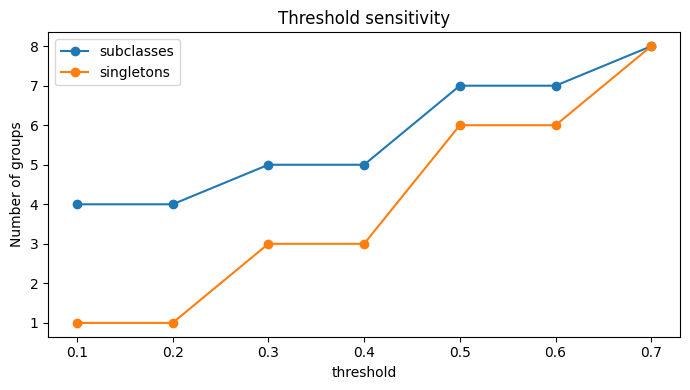

Radius 0 same accepted edges: True
Radius 10 same accepted edges: True
Radius 20 same accepted edges: True


Radius 50 same accepted edges: True


In [5]:
sensitivity=pd.DataFrame([{"threshold":t,**summary(*grouping(valid,scores,t))} for t in [.1,.2,.3,.4,.5,.6,.7]])
display(sensitivity.round(3))
fig,ax=plt.subplots(figsize=(7,4))
sensitivity.plot(x="threshold",y=["subclasses","singletons"],marker="o",ax=ax)
ax.set_ylabel("Number of groups"); ax.set_title("Threshold sensitivity"); plt.tight_layout(); plt.show()
base_edges={frozenset(e) for e in G.edges}
for r in [0,10,20,50]:
    graph,_=grouping(valid,candidate_scores(valid,r),.3)
    print("Radius",r,"same accepted edges:", {frozenset(e) for e in graph.edges}==base_edges)

## 5. Controlled geometry tests
These fictional examples test the behavior of IoU and transitive grouping. They do not demonstrate real-world generalisation.

In [6]:
a=box(0,0,10,10)
examples=[("identical",a,1), ("shifted",box(2,0,12,10),2/3),
          ("near but disjoint",box(11,0,21,10),0), ("nested",box(2,2,7,7),.25)]
for name,b,expected in examples:
    value=iou(a,b)
    assert abs(value-expected)<1e-9
    print(name,round(value,3),"edge:",value>=.3)
a,b,c=box(0,0,10,10),box(4,0,14,10),box(8,0,18,10)
assert iou(a,b)>=.3 and iou(b,c)>=.3 and iou(a,c)<.3
print("PASS: chaining example", [round(iou(x,y),3) for x,y in [(a,b),(b,c),(a,c)]])

identical 1.0 edge: True
shifted 0.667 edge: True
near but disjoint 0.0 edge: False
nested 0.25 edge: False
PASS: chaining example [0.429, 0.429, 0.111]


## 6. Reflection and next steps
- Fixed IoU cannot match disjoint geometries even if they refer to the same place.
- Connected components can chain weakly related objects; category splitting occurs after graph construction.
- ID-aligned flags fix row assignment, not the scientific validity of the anomaly rule.
- Compare local projected CRS, alternative similarity measures, and independently labelled place matches in future work.
- AI-assisted notebook preparation and execution must be distinguished from the original coursework and independently reviewed by the applicant before claiming personal proficiency.